In [63]:
# Import necessary libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,f1_score,confusion_matrix,classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


In [64]:
# Load the dataset
data = pd.read_csv("loandata.csv")

In [65]:
# Explore the dataset
data.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [66]:
data

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


In [67]:
data.Loan_ID.value_counts(dropna=False)

Loan_ID
LP001002    1
LP001003    1
LP001005    1
LP001006    1
LP001008    1
           ..
LP002978    1
LP002979    1
LP002983    1
LP002984    1
LP002990    1
Name: count, Length: 614, dtype: int64

In [68]:
x =data.isnull().sum()
x

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [69]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 83.4 KB


In [70]:
data.shape

(614, 13)

In [71]:
data['Property_Area'].describe()

count           614
unique            3
top       Semiurban
freq            233
Name: Property_Area, dtype: object

In [72]:
data['ApplicantIncome'].describe()

count      614.000000
mean      5403.459283
std       6109.041673
min        150.000000
25%       2877.500000
50%       3812.500000
75%       5795.000000
max      81000.000000
Name: ApplicantIncome, dtype: float64

In [73]:
df=data['Property_Area'].value_counts().reset_index()

In [74]:
df.columns=['Area','count']

In [75]:
df

,Area,count
0,Semiurban,233
1,Urban,202
2,Rural,179


In [76]:
data['ApplicantIncome'][data['Gender']=="Male"].mean()

np.float64(5446.460122699386)

In [77]:
data['Property_Area'][data['Loan_Status']=='Y'].value_counts()

Property_Area
Semiurban    179
Urban        133
Rural        110
Name: count, dtype: int64

In [78]:
data['Property_Area'][data['Loan_Status']=='N'].value_counts()

Property_Area
Rural        69
Urban        69
Semiurban    54
Name: count, dtype: int64

In [79]:
data.groupby('Gender')['Property_Area'].value_counts()

Gender  Property_Area
Female  Semiurban         55
        Urban             33
        Rural             24
Male    Semiurban        172
        Urban            166
        Rural            151
Name: count, dtype: int64

In [80]:
data.groupby('Gender')['ApplicantIncome'].mean()

Gender
Female    4643.473214
Male      5446.460123
Name: ApplicantIncome, dtype: float64

In [81]:
%matplotlib inline

In [82]:
df=data.groupby('Gender')['ApplicantIncome'].mean()

Number of applicants income who has taken loan


<Axes: xlabel='Gender'>

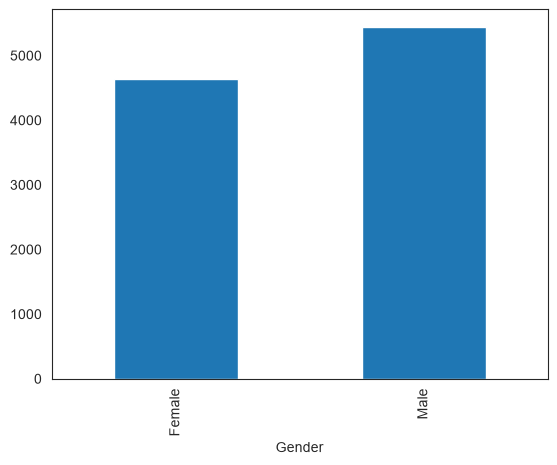

In [83]:
print("Number of applicants income who has taken loan")
df.plot(kind='bar')

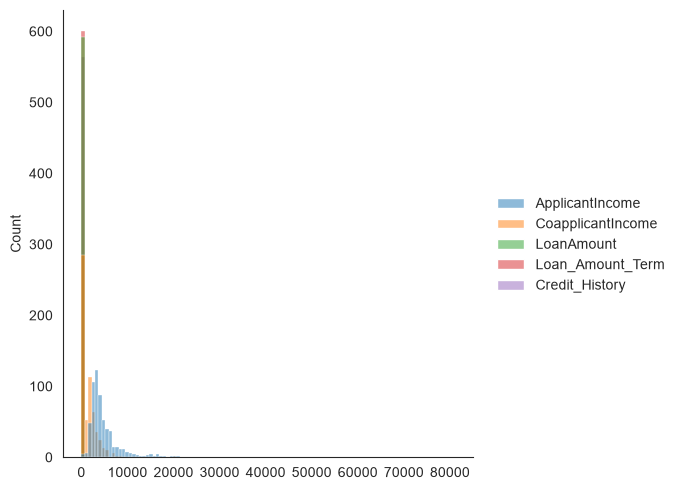

In [84]:
sns.displot(data)

<Axes: >

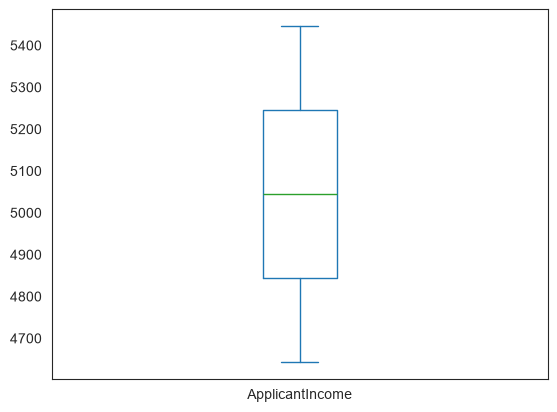

In [85]:
df.plot.box()

Number of people who took loan by gender
Gender
Male      489
Female    112
Name: count, dtype: int64


<Axes: xlabel='Gender', ylabel='count'>

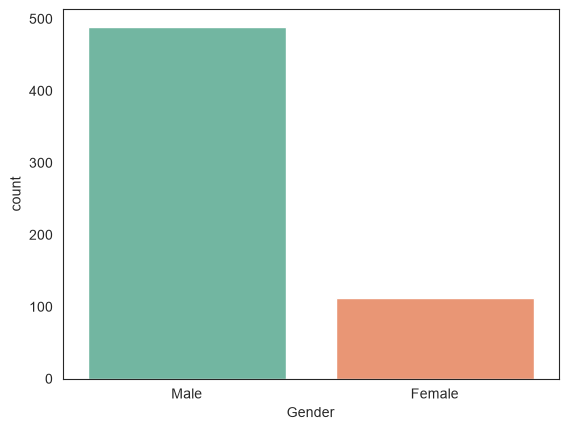

In [86]:
print("Number of people who took loan by gender")
print(data['Gender'].value_counts())
sns.countplot(x='Gender',data=data,palette='Set2')

In [87]:
data.Married.value_counts(dropna=False)

Married
Yes    398
No     213
NaN      3
Name: count, dtype: int64

<Axes: >

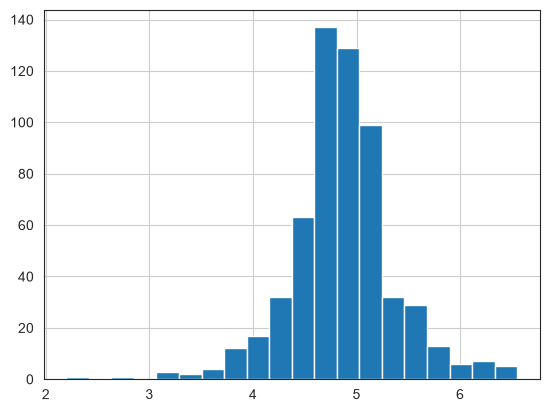

In [88]:
data['LoanAmount_log']=np.log(data['LoanAmount'])
data['LoanAmount_log'].hist(bins=20)

In [89]:
# Fill missing values (assign back instead of inplace=True, which no longer works on a column in pandas 3)
for col in ['Gender', 'Married', 'Dependents', 'Self_Employed', 'Loan_Amount_Term', 'Credit_History']:
    data[col] = data[col].fillna(data[col].mode()[0])
data['LoanAmount'] = data['LoanAmount'].fillna(data['LoanAmount'].mean())
data['LoanAmount_log'] = data['LoanAmount_log'].fillna(data['LoanAmount_log'].mean())

In [90]:
data

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,LoanAmount_log
0,LP001002,Male,No,0,Graduate,No,5849,0.0,146.412162,360.0,1.0,Urban,Y,4.857444
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.000000,360.0,1.0,Rural,N,4.852030
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.000000,360.0,1.0,Urban,Y,4.189655
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.000000,360.0,1.0,Urban,Y,4.787492
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.000000,360.0,1.0,Urban,Y,4.948760
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.000000,360.0,1.0,Rural,Y,4.262680
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.000000,180.0,1.0,Rural,Y,3.688879
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.000000,360.0,1.0,Urban,Y,5.533389
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.000000,360.0,1.0,Urban,Y,5.231109


In [91]:
data.groupby('Gender').agg({'ApplicantIncome':['sum','mean'],'CoapplicantIncome':['sum','mean']})

ApplicantIncome              CoapplicantIncome             
                   sum         mean               sum         mean
Gender                                                            
Female          520069  4643.473214     124097.000000  1108.008929
Male           2797655  5573.017928     871347.919989  1735.752829

In [92]:
data[['Loan_Status','Credit_History']].value_counts()

Loan_Status  Credit_History
Y            1.0               415
N            1.0               110
             0.0                82
Y            0.0                 7
Name: count, dtype: int64

In [93]:
pd.crosstab(index=data['Loan_Status'], columns=data['Credit_History'])

Credit_History,0.0,1.0
Loan_Status,,
N,82,110
Y,7,415


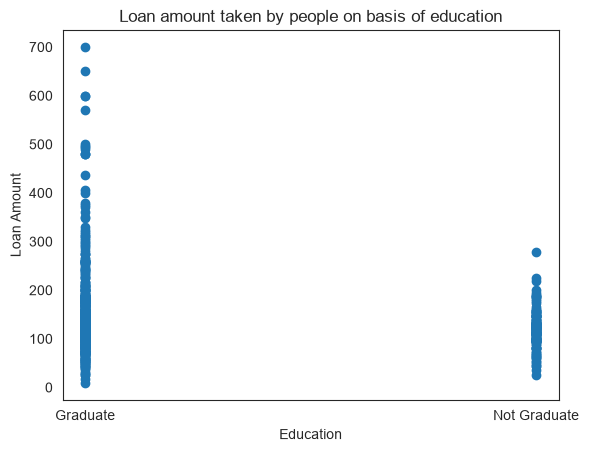

In [94]:
plt.title('Loan amount taken by people on basis of education')
plt.xlabel('Education')
plt.ylabel('Loan Amount')
plt.scatter(data['Education'],data['LoanAmount'])

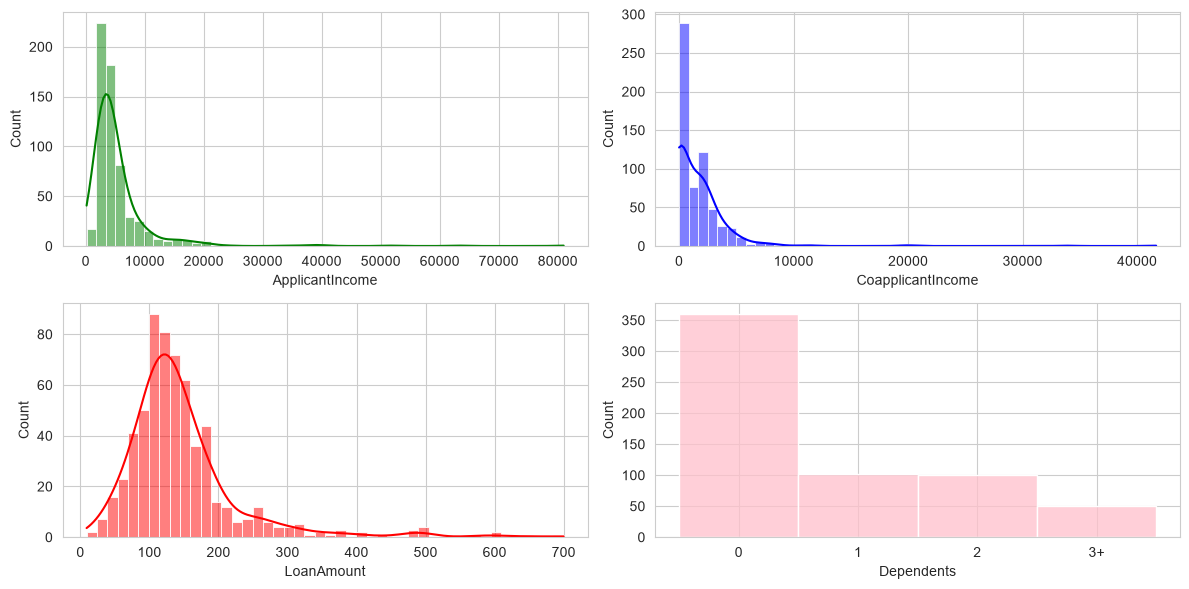

In [95]:
sns.set_style("whitegrid")
fig, axs = plt.subplots(2, 2, figsize=(12, 6))
sns.histplot(data=data, x='ApplicantIncome', kde=True, color='green', ax=axs[0,0])
sns.histplot(data=data, x='CoapplicantIncome', kde=True, color='blue', ax=axs[0,1])
sns.histplot(data=data, x='LoanAmount', kde=True, color='red', ax=axs[1,0])
sns.histplot(data=data, x='Dependents', color='pink', ax=axs[1,1])  # categorical (0,1,2,3+), so no kde
plt.tight_layout()
plt.show()

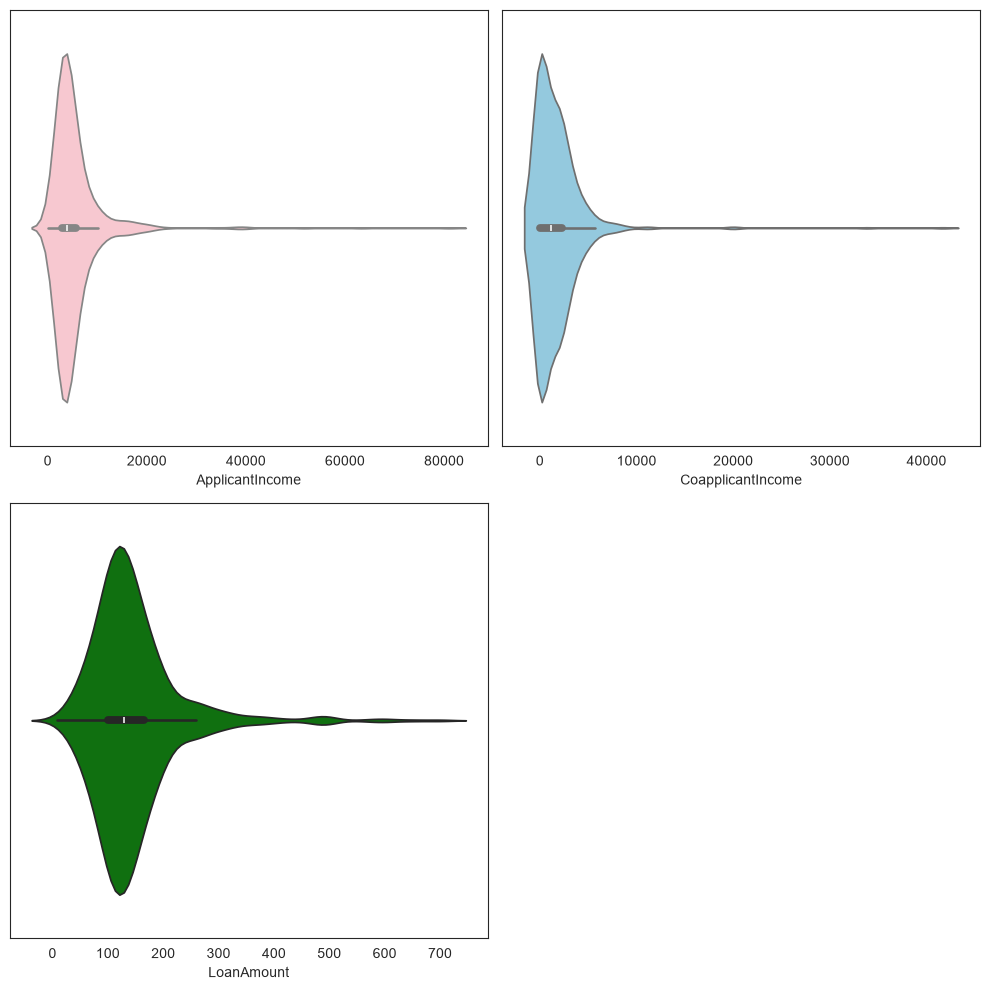

In [96]:
sns.set_style("white")   # call it as a function, don't assign a string to it
fig, axs = plt.subplots(2, 2, figsize=(10, 10))
sns.violinplot(data=data, x='ApplicantIncome', color='pink', ax=axs[0,0])
sns.violinplot(data=data, x='CoapplicantIncome', color='skyblue', ax=axs[0,1])
sns.violinplot(data=data, x='LoanAmount', color='green', ax=axs[1,0])
axs[1,1].axis('off')   # unused 4th panel
plt.tight_layout()
plt.show()

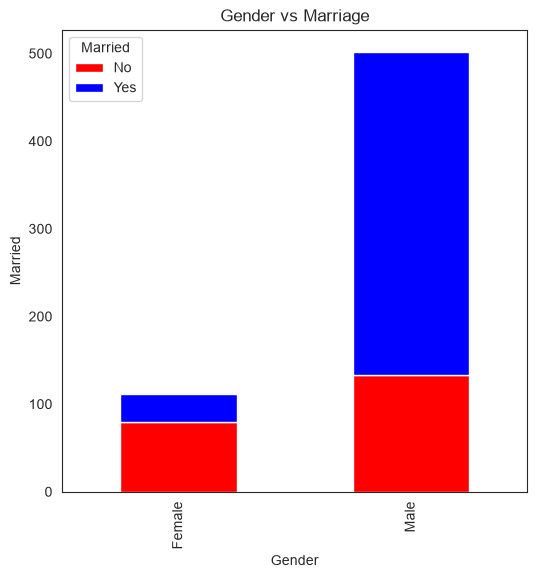

In [97]:
pd.crosstab(data.Gender,data.Married).plot(kind='bar',stacked=True,figsize=(6,6),color=['red','blue'])
plt.xlabel('Gender')
plt.ylabel('Married')
plt.title('Gender vs Marriage')
plt.show()

Number of people who took loan by Loanamount
LoanAmount
146.412162    22
120.000000    20
110.000000    17
100.000000    15
187.000000    12
              ..
292.000000     1
142.000000     1
350.000000     1
496.000000     1
253.000000     1
Name: count, Length: 204, dtype: int64


<Axes: xlabel='LoanAmount', ylabel='count'>

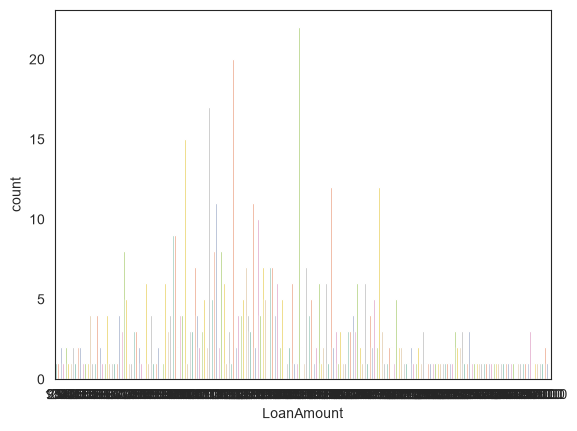

In [98]:
print("Number of people who took loan by Loanamount")
print(data['LoanAmount'].value_counts())
sns.countplot(x='LoanAmount',data=data,palette='Set2')

Number of people who took loan by CreditHistory
Credit_History
1.0    525
0.0     89
Name: count, dtype: int64


<Axes: xlabel='Credit_History', ylabel='count'>

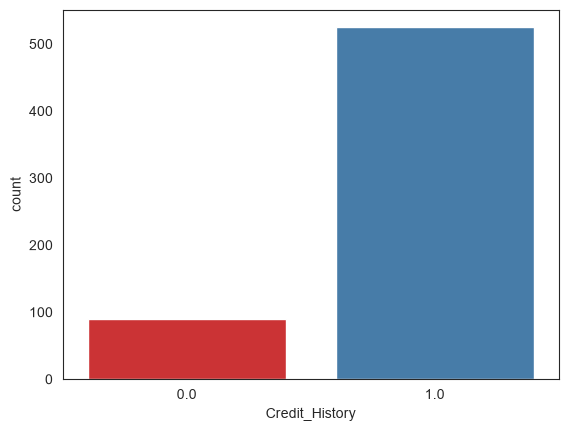

In [99]:
print("Number of people who took loan by CreditHistory")
print(data['Credit_History'].value_counts())
sns.countplot(x='Credit_History',data=data,palette='Set1')

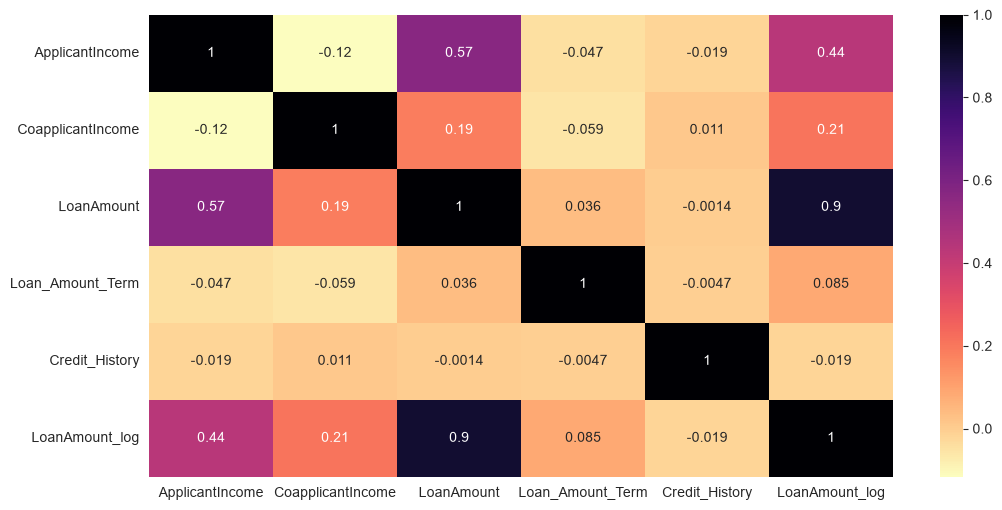

In [100]:
#Heatmap of Dataset
plt.figure(figsize=(12,6))
sns.heatmap(data.corr(numeric_only=True), annot=True, cmap='magma_r')
plt.show()

In [101]:
### label encoding
from sklearn.preprocessing import LabelEncoder

# Loan_ID is just an identifier, not a useful feature
data = data.drop(columns=['Loan_ID'])

# Encode every text column (a model can't use strings)
for col in data.select_dtypes(include=['object', 'string']).columns:
    data[col] = LabelEncoder().fit_transform(data[col].astype(str))

In [102]:
data

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,LoanAmount_log
0,1,0,0,0,0,5849,0.0,146.412162,360.0,1.0,2,1,4.857444
1,1,1,1,0,0,4583,1508.0,128.000000,360.0,1.0,0,0,4.852030
2,1,1,0,0,1,3000,0.0,66.000000,360.0,1.0,2,1,4.189655
3,1,1,0,1,0,2583,2358.0,120.000000,360.0,1.0,2,1,4.787492
4,1,0,0,0,0,6000,0.0,141.000000,360.0,1.0,2,1,4.948760
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,0,0,0,0,0,2900,0.0,71.000000,360.0,1.0,0,1,4.262680
610,1,1,3,0,0,4106,0.0,40.000000,180.0,1.0,0,1,3.688879
611,1,1,1,0,0,8072,240.0,253.000000,360.0,1.0,2,1,5.533389
612,1,1,2,0,0,7583,0.0,187.000000,360.0,1.0,2,1,5.231109


In [117]:
### label encoding
from sklearn.preprocessing import LabelEncoder

# Encode every text column (a model can't use strings)
for col in data.select_dtypes(include=['object', 'string']).columns:
    data[col] = LabelEncoder().fit_transform(data[col].astype(str))

In [118]:
y = data['Loan_Status']
x = data.drop(columns=['Loan_Status'])

In [119]:
x

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,LoanAmount_log
0,1,0,0,0,0,5849,0.0,146.412162,360.0,1.0,2,4.857444
1,1,1,1,0,0,4583,1508.0,128.000000,360.0,1.0,0,4.852030
2,1,1,0,0,1,3000,0.0,66.000000,360.0,1.0,2,4.189655
3,1,1,0,1,0,2583,2358.0,120.000000,360.0,1.0,2,4.787492
4,1,0,0,0,0,6000,0.0,141.000000,360.0,1.0,2,4.948760
...,...,...,...,...,...,...,...,...,...,...,...,...
609,0,0,0,0,0,2900,0.0,71.000000,360.0,1.0,0,4.262680
610,1,1,3,0,0,4106,0.0,40.000000,180.0,1.0,0,3.688879
611,1,1,1,0,0,8072,240.0,253.000000,360.0,1.0,2,5.533389
612,1,1,2,0,0,7583,0.0,187.000000,360.0,1.0,2,5.231109


In [120]:
y

0      1
1      0
2      1
3      1
4      1
      ..
609    1
610    1
611    1
612    1
613    0
Name: Loan_Status, Length: 614, dtype: int64

In [131]:
x

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,LoanAmount_log
0,1,0,0,0,0,5849,0.0,146.412162,360.0,1.0,2,4.857444
1,1,1,1,0,0,4583,1508.0,128.000000,360.0,1.0,0,4.852030
2,1,1,0,0,1,3000,0.0,66.000000,360.0,1.0,2,4.189655
3,1,1,0,1,0,2583,2358.0,120.000000,360.0,1.0,2,4.787492
4,1,0,0,0,0,6000,0.0,141.000000,360.0,1.0,2,4.948760
...,...,...,...,...,...,...,...,...,...,...,...,...
609,0,0,0,0,0,2900,0.0,71.000000,360.0,1.0,0,4.262680
610,1,1,3,0,0,4106,0.0,40.000000,180.0,1.0,0,3.688879
611,1,1,1,0,0,8072,240.0,253.000000,360.0,1.0,2,5.533389
612,1,1,2,0,0,7583,0.0,187.000000,360.0,1.0,2,5.231109


In [122]:
x_train,x_test,y_train,y_test  = train_test_split(x,y,test_size=0.25,random_state=30)

In [123]:
x_train.shape

(460, 12)

In [124]:
x_test.shape

(154, 12)

In [125]:
x.shape

(614, 12)

In [126]:
# Train a model and check accuracy
model = RandomForestClassifier(random_state=30)
model.fit(x_train, y_train)
print("Accuracy:", accuracy_score(y_test, model.predict(x_test)))

Accuracy: 0.7142857142857143


In [127]:
accuracy_score(y_test, model.predict(x_test))

0.7142857142857143

In [128]:
f1_score(y_test, model.predict(x_test))

0.8070175438596491

In [129]:
confusion_matrix(y_test, model.predict(x_test))

array([[18, 27],
       [17, 92]])

In [130]:
print (classification_report(y_test, model.predict(x_test)))

              precision    recall  f1-score   support

           0       0.51      0.40      0.45        45
           1       0.77      0.84      0.81       109

    accuracy                           0.71       154
   macro avg       0.64      0.62      0.63       154
weighted avg       0.70      0.71      0.70       154

